<a href="https://colab.research.google.com/github/gezahagnhailegnaw71-a11y/numerical_practice/blob/main/Newton_Raphson_Method_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Newton–Raphson Method
**Numerical Analysis · Lab · Final version**

**Problem.** Solve $f(x)=0$.

**Idea.** At the current guess $x_k$, draw the **tangent line** to the curve $y=f(x)$. The tangent crosses the $x$-axis at a new point $x_{k+1}$, which is usually much closer to the root.

The tangent at $x_k$ is $y=f(x_k)+f'(x_k)(x-x_k)$. Setting $y=0$ gives

$$\boxed{\,x_{k+1}=x_k-\frac{f(x_k)}{f'(x_k)}\,}$$

Stop when $\lvert x_{k+1}-x_k\rvert<\text{tol}$.

| | Newton–Raphson |
|---|---|
| Needs | $f$, its derivative $f'$, and **one** starting guess $x_0$ |
| Speed | **quadratic**: the number of correct digits roughly **doubles** every step |
| Danger | $f'(x_k)=0$; a bad $x_0$ can make it cycle or diverge; slow at a double root |

## Step 1: Import

In [ ]:
import math

## Step 2: Notation (quick reminder)
The **full notation guide** (math symbols, the meaning of `f`, all format codes, how to build a table) is in **Bisection_Method_Final.ipynb**.

| Format code | Meaning | Example |
|---|---|---|
| `f"{x:>14.10f}"` | right aligned, width 14, 10 decimals | `  1.3652300134` |
| `f"{x:>12.2e}"` | scientific notation | `    5.02e-10` |
| `f"{n:>5d}"` | whole number, width 5 | `    7` |

### New in Newton's method
| Notation | Meaning |
|---|---|
| `df(x)` | the **derivative** $f'(x)$. We write it ourselves, e.g. $f=x^3+4x^2-10 \Rightarrow f'=3x^2+8x$ |
| `x0` | the starting guess $x_0$ |
| `x_new = x - f(x) / df(x)` | one Newton step $x_{k+1}=x_k-\dfrac{f(x_k)}{f'(x_k)}$ |
| `if df(x) == 0:` | a horizontal tangent never meets the $x$-axis: we must stop |
| `abs(x_new - x) < tol` | two answers almost the same, so **stop** |
| `max_iter` | safety limit on the number of steps |
| `return None, table` | `None` means "no answer" (the method failed) |

## Step 3: Write the functions
### 3a. `print_table`: prints the steps as a table
We write the printing **once**, so every version of the method can use it.

In [ ]:
COLUMNS = ["step", "x_k", "f(x_k)", "f'(x_k)", "x_{k+1}", "|step|"]

def print_table(table):
    # header, line, one row for each step, line
    print(f"{'step':>5} {'x_k':>14} {'f(x_k)':>12} {'df(x_k)':>12} {'x_k+1':>14} {'|step|':>12}")
    print("-" * 74)
    for row in table:
        print(f"{row[0]:>5d} {row[1]:>14.10f} {row[2]:>12.2e} {row[3]:>12.6f} {row[4]:>14.10f} {row[5]:>12.2e}")
    print("-" * 74)

### 3b. `newton` with a `for` loop
The loop runs at most `max_iter` times and stops early with `break` when two answers are almost the same.

In [ ]:
def newton(f, df, x0, tol=1e-6, max_iter=50, show=True):
    # f       : the function in f(x) = 0
    # df      : its derivative f'(x)
    # x0      : the starting guess
    # tol     : stop when two answers differ by less than tol
    # max_iter: safety limit on the number of steps
    # show    : True = print the table

    table = []                                     # one row for each step
    x = x0
    converged = False

    for step in range(1, max_iter + 1):            # at most max_iter steps
        fx = f(x)
        dfx = df(x)

        if dfx == 0:                               # horizontal tangent: cannot continue
            if show:
                print(f"Stopped at step {step}: f'(x) = 0 at x = {x} (horizontal tangent)")
            return None, table

        x_new = x - fx / dfx                       # Newton step
        table.append([step, x, fx, dfx, x_new, abs(x_new - x)])   # save this row

        if abs(x_new - x) < tol:                   # two answers almost the same: stop
            converged = True
            x = x_new
            break
        x = x_new                                  # new value becomes the old value

    if show:
        print_table(table)
        if converged:
            print(f"Root = {x:.10f}   (found in {step} steps)\n")
        else:
            print(f"WARNING: no convergence after {max_iter} steps. Last value = {x}\n")

    return x, table

## Step 4: Example 1 — $x^3+4x^2-10=0$, $\;x_0=1.5$
$f(x)=x^3+4x^2-10$, $\;f'(x)=3x^2+8x$.

In [ ]:
def f1(x):
    return x**3 + 4*x**2 - 10

def df1(x):
    return 3*x**2 + 8*x

root, table = newton(f1, df1, 1.5)

 step            x_k       f(x_k)      df(x_k)          x_k+1       |step|
--------------------------------------------------------------------------
    1   1.5000000000     2.38e+00    18.750000   1.3733333333     1.27e-01
    2   1.3733333333     1.34e-01    16.644800   1.3652620149     8.07e-03
    3   1.3652620149     5.28e-04    16.513917   1.3652300139     3.20e-05
    4   1.3652300139     8.29e-09    16.513399   1.3652300134     5.02e-10
--------------------------------------------------------------------------
Root = 1.3652300134   (found in 4 steps)



Look at the column `|step|`: $10^{-1}\to10^{-3}\to10^{-5}\to10^{-10}$. The exponent roughly **doubles** each step: this is **quadratic convergence**. Bisection needed 20 steps for $10^{-6}$; Newton needs 4.

## Step 5: More examples
For each equation we write `f(x)` **and** its derivative `df(x)`, then call `newton`.

In [ ]:
# Example 2:  cos(x) - x = 0,  x0 = 1
def f2(x):
    return math.cos(x) - x

def df2(x):
    return -math.sin(x) - 1

root, table = newton(f2, df2, 1.0)

 step            x_k       f(x_k)      df(x_k)          x_k+1       |step|
--------------------------------------------------------------------------
    1   1.0000000000    -4.60e-01    -1.841471   0.7503638678     2.50e-01
    2   0.7503638678    -1.89e-02    -1.681905   0.7391128909     1.13e-02
    3   0.7391128909    -4.65e-05    -1.673633   0.7390851334     2.78e-05
    4   0.7390851334    -2.85e-10    -1.673612   0.7390851332     1.70e-10
--------------------------------------------------------------------------
Root = 0.7390851332   (found in 4 steps)



In [ ]:
# Example 3:  x^2 - 2 = 0,  x0 = 1   (the root is the square root of 2)
def f3(x):
    return x**2 - 2

def df3(x):
    return 2*x

root, table = newton(f3, df3, 1.0)

 step            x_k       f(x_k)      df(x_k)          x_k+1       |step|
--------------------------------------------------------------------------
    1   1.0000000000    -1.00e+00     2.000000   1.5000000000     5.00e-01
    2   1.5000000000     2.50e-01     3.000000   1.4166666667     8.33e-02
    3   1.4166666667     6.94e-03     2.833333   1.4142156863     2.45e-03
    4   1.4142156863     6.01e-06     2.828431   1.4142135624     2.12e-06
    5   1.4142135624     4.51e-12     2.828427   1.4142135624     1.59e-12
--------------------------------------------------------------------------
Root = 1.4142135624   (found in 5 steps)



In [ ]:
# Example 4:  x^3 - x - 2 = 0,  x0 = 1.5
def f4(x):
    return x**3 - x - 2

def df4(x):
    return 3*x**2 - 1

root, table = newton(f4, df4, 1.5)

 step            x_k       f(x_k)      df(x_k)          x_k+1       |step|
--------------------------------------------------------------------------
    1   1.5000000000    -1.25e-01     5.750000   1.5217391304     2.17e-02
    2   1.5217391304     2.14e-03     5.947070   1.5213798060     3.59e-04
    3   1.5213798060     5.89e-07     5.943790   1.5213797068     9.92e-08
--------------------------------------------------------------------------
Root = 1.5213797068   (found in 3 steps)



In [ ]:
# Example 5:  e^x - 3x = 0,  x0 = 0   (smallest root)
def f5(x):
    return math.exp(x) - 3*x

def df5(x):
    return math.exp(x) - 3

root, table = newton(f5, df5, 0.0)

 step            x_k       f(x_k)      df(x_k)          x_k+1       |step|
--------------------------------------------------------------------------
    1   0.0000000000     1.00e+00    -2.000000   0.5000000000     5.00e-01
    2   0.5000000000     1.49e-01    -1.351279   0.6100596550     1.10e-01
    3   0.6100596550     1.04e-02    -1.159459   0.6189967797     8.94e-03
    4   0.6189967797     7.37e-05    -1.142936   0.6190612834     6.45e-05
    5   0.6190612834     3.86e-09    -1.142816   0.6190612867     3.38e-09
--------------------------------------------------------------------------
Root = 0.6190612867   (found in 5 steps)



**Same equation, different $x_0$, different root.** $e^x-3x=0$ has **two** roots. Newton finds the one "near" the starting guess:

In [ ]:
root, table = newton(f5, df5, 2.0)

 step            x_k       f(x_k)      df(x_k)          x_k+1       |step|
--------------------------------------------------------------------------
    1   2.0000000000     1.39e+00     4.389056   1.6835182628     3.16e-01
    2   1.6835182628     3.34e-01     2.384467   1.5434819721     1.40e-01
    3   1.5434819721     5.04e-02     1.680861   1.5134886228     3.00e-02
    4   1.5134886228     2.08e-03     1.542550   1.5121372501     1.35e-03
    5   1.5121372501     4.15e-06     1.536416   1.5121345517     2.70e-06
    6   1.5121345517     1.65e-11     1.536404   1.5121345517     1.08e-11
--------------------------------------------------------------------------
Root = 1.5121345517   (found in 6 steps)



## Step 6: Correct digits double every step
We compare each $x_k$ with the true root $p$ and count the correct digits $\approx-\log_{10}\lvert x_k-p\rvert$.

In [ ]:
p = 1.365230013414097                          # true root of f1
root, table = newton(f1, df1, 1.5, tol=1e-15, show=False)

print(f"{'step':>5} {'x_k+1':>20} {'error |x - p|':>15} {'correct digits':>16}")
print("-" * 59)
for row in table:
    err = abs(row[4] - p)
    digits = -math.log10(err) if err > 0 else 16      # 16 = all digits a computer can store
    print(f"{row[0]:>5d} {row[4]:>20.15f} {err:>15.2e} {digits:>16.1f}")

 step                x_k+1   error |x - p|   correct digits
-----------------------------------------------------------
    1    1.373333333333333        8.10e-03              2.1
    2    1.365262014874627        3.20e-05              4.5
    3    1.365230013916147        5.02e-10              9.3
    4    1.365230013414097        2.22e-16             15.7
    5    1.365230013414097        2.22e-16             15.7


## Step 7: When Newton's method fails
Newton is fast, but only if $x_0$ is **close enough** to the root and $f'(p)\neq0$.

**Failure 1: horizontal tangent.** $f(x)=x^2-1$ with $x_0=0$: $f'(0)=0$.

In [ ]:
root, table = newton(lambda x: x**2 - 1, lambda x: 2*x, 0.0)

Stopped at step 1: f'(x) = 0 at x = 0.0 (horizontal tangent)


**Failure 2: a cycle.** $f(x)=x^3-2x+2$ with $x_0=0$: it jumps $0\to1\to0\to1\dots$ forever.

In [ ]:
def f6(x):
    return x**3 - 2*x + 2

def df6(x):
    return 3*x**2 - 2

root, table = newton(f6, df6, 0.0, max_iter=6)

 step            x_k       f(x_k)      df(x_k)          x_k+1       |step|
--------------------------------------------------------------------------
    1   0.0000000000     2.00e+00    -2.000000   1.0000000000     1.00e+00
    2   1.0000000000     1.00e+00     1.000000   0.0000000000     1.00e+00
    3   0.0000000000     2.00e+00    -2.000000   1.0000000000     1.00e+00
    4   1.0000000000     1.00e+00     1.000000   0.0000000000     1.00e+00
    5   0.0000000000     2.00e+00    -2.000000   1.0000000000     1.00e+00
    6   1.0000000000     1.00e+00     1.000000   0.0000000000     1.00e+00
--------------------------------------------------------------------------



**Failure 3: divergence.** $f(x)=\arctan x$ (root $0$) with $x_0=1.5$: each tangent overshoots further.

In [ ]:
def f7(x):
    return math.atan(x)

def df7(x):
    return 1 / (1 + x**2)

root, table = newton(f7, df7, 1.5, max_iter=6)
print("From x0 = 1.0 instead it converges:")
root, table = newton(f7, df7, 1.0)

 step            x_k       f(x_k)      df(x_k)          x_k+1       |step|
--------------------------------------------------------------------------
    1   1.5000000000     9.83e-01     0.307692  -1.6940796006     3.19e+00
    2  -1.6940796006    -1.04e+00     0.258404   2.3211269614     4.02e+00
    3   2.3211269614     1.16e+00     0.156553  -5.1140878368     7.44e+00
    4  -5.1140878368    -1.38e+00     0.036827  32.2956839142     3.74e+01
    5  32.2956839142     1.54e+00     0.000958 -1575.3169508212     1.61e+03
    6 -1575.3169508212    -1.57e+00     0.000000 3894976.0077608819     3.90e+06
--------------------------------------------------------------------------

From x0 = 1.0 instead it converges:
 step            x_k       f(x_k)      df(x_k)          x_k+1       |step|
--------------------------------------------------------------------------
    1   1.0000000000     7.85e-01     0.500000  -0.5707963268     1.57e+00
    2  -0.5707963268    -5.19e-01     0.754257   0.1168

**Failure 4: a double root is slow.** $f(x)=(x-1)^2(x+2)$ touches the axis at $x=1$ without crossing it. Newton still converges, but only **linearly**. The fix for a root of multiplicity $m$ is $x_{k+1}=x_k-m\,\dfrac{f(x_k)}{f'(x_k)}$.

In [ ]:
def f8(x):
    return (x - 1)**2 * (x + 2)

def df8(x):
    return 2*(x - 1)*(x + 2) + (x - 1)**2

root, table = newton(f8, df8, 2.0, tol=1e-10, show=False)
print("plain Newton   :", len(table), "steps")

root, table = newton(f8, lambda x: df8(x) / 2, 2.0, tol=1e-10, show=False)   # m = 2:  x - 2 f/f'
print("modified Newton:", len(table), "steps")

plain Newton   : 34 steps
modified Newton: 5 steps


## Step 8: Animations — watch the tangent lines
Each frame draws **one** tangent: from the point $(x_k, f(x_k))$ on the curve down to the $x$-axis at $x_{k+1}$, then up to the curve again. Press ▶.

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
plt.rcParams["animation.embed_limit"] = 40          # allow bigger animations in the notebook

def curve_points(f, xmin, xmax, n=400):
    # x and y values of the curve y = f(x) for plotting (nan where f cannot be computed)
    xs = [xmin + (xmax - xmin) * i / n for i in range(n + 1)]
    ys = []
    for x in xs:
        try:
            ys.append(f(x))
        except (ValueError, OverflowError, ZeroDivisionError):
            ys.append(float("nan"))
    return xs, ys

def animate_newton(f, df, x0, xmin, xmax, ymin, ymax, steps=5, title=""):
    # 1. compute x0, x1, x2, ...
    xs_it = [x0]
    for _ in range(steps):
        x = xs_it[-1]
        if df(x) == 0:
            break
        xs_it.append(x - f(x) / df(x))

    cx, cy = curve_points(f, xmin, xmax)
    fig, ax = plt.subplots(figsize=(7, 4.5))

    def draw(frame):                               # the picture after `frame` steps
        ax.clear()
        ax.plot(cx, cy, color="#1f77b4", lw=2, label="y = f(x)")
        ax.axhline(0, color="k", lw=0.8)
        for k in range(frame):
            x, x_new = xs_it[k], xs_it[k + 1]
            ax.plot([x, x], [0, f(x)], ":", color="grey")              # up to the curve
            ax.plot([x, x_new], [f(x), 0], color="red", lw=1.6)        # tangent down to the axis
            ax.plot(x, f(x), "o", color="red", ms=5)
        xk = xs_it[frame]
        ax.plot(xk, 0, "o", color="black", ms=7)
        ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax); ax.grid(alpha=0.3); ax.legend(loc="upper left")
        ax.set_title(f"{title}\nstep {frame}:  x_{frame} = {xk:.10f}")

    anim = FuncAnimation(fig, draw, frames=len(xs_it), interval=1000)
    plt.close(fig)
    return HTML(anim.to_jshtml(default_mode="once"))

### Converges: $x^3+4x^2-10$, $\;x_0=2.5$

In [ ]:
animate_newton(f1, df1, 2.5, 1.2, 2.7, -6, 35, steps=4, title="x^3 + 4x^2 - 10 (converges)")

### Cycles: $x^3-2x+2$, $\;x_0=0$

In [ ]:
animate_newton(f6, df6, 0.0, -2.2, 1.6, -3, 5, steps=6, title="x^3 - 2x + 2 (cycles 0, 1, 0, 1, ...)")

### Diverges: $\arctan x$, $\;x_0=1.45$

In [ ]:
animate_newton(f7, df7, 1.45, -12, 12, -1.8, 1.8, steps=4, title="arctan x (overshoots: diverges)")

## Step 9 (optional): The table with pandas

In [ ]:
import pandas as pd

root, table = newton(f1, df1, 1.5, show=False)
pd.DataFrame(table, columns=COLUMNS).set_index("step")

,x_k,f(x_k),f'(x_k),x_{k+1},|step|
step,,,,,
1,1.500000,2.375000e+00,18.750000,1.373333,1.266667e-01
2,1.373333,1.343455e-01,16.644800,1.365262,8.071318e-03
3,1.365262,5.284612e-04,16.513917,1.365230,3.200096e-05
4,1.365230,8.290549e-09,16.513399,1.365230,5.020497e-10


## Step 10 (optional): Let the computer find the derivative (SymPy)
If the derivative is hard to write by hand, `sympy` can compute it for us.

In [ ]:
import sympy as sp

X = sp.symbols("x")
expr = X * sp.exp(X) - 2                     # solve  x e^x - 2 = 0
dexpr = sp.diff(expr, X)                     # SymPy finds the derivative
print("f(x)  =", expr)
print("f'(x) =", dexpr)

f9 = sp.lambdify(X, expr, "math")            # turn the formulas into Python functions
df9 = sp.lambdify(X, dexpr, "math")
root, table = newton(f9, df9, 1.0)

f(x)  = x*exp(x) - 2
f'(x) = x*exp(x) + exp(x)
 step            x_k       f(x_k)      df(x_k)          x_k+1       |step|
--------------------------------------------------------------------------
    1   1.0000000000     7.18e-01     5.436564   0.8678794412     1.32e-01
    2   0.8678794412     6.72e-02     4.449017   0.8527833734     1.51e-02
    3   0.8527833734     7.73e-04     4.346941   0.8526055264     1.78e-04
    4   0.8526055264     1.06e-07     4.345751   0.8526055020     2.44e-08
--------------------------------------------------------------------------
Root = 0.8526055020   (found in 4 steps)



## Step 11 (optional): Error at each step

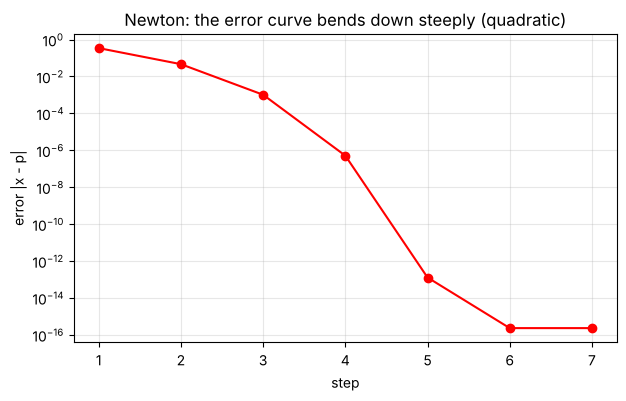

In [ ]:
p = 1.365230013414097
root, table = newton(f1, df1, 2.5, tol=1e-15, show=False)
errors = [abs(row[4] - p) + 1e-17 for row in table]
plt.figure(figsize=(7, 4))
plt.semilogy(range(1, len(errors) + 1), errors, "o-", color="red")
plt.xlabel("step"); plt.ylabel("error |x - p|"); plt.grid(alpha=0.3)
plt.title("Newton: the error curve bends down steeply (quadratic)"); plt.show()

## Step 12: The same method with a `while` loop
A `for` loop runs at most `max_iter` times and leaves early with `break`.
A `while` loop repeats **while** a condition is true. Here: while the two last answers are still far apart **and** we have not reached `max_iter`.

To start the loop we set `diff = tol + 1` (a number bigger than `tol`), so the condition is true the first time.

In [ ]:
def newton_while(f, df, x0, tol=1e-6, max_iter=50, show=True):
    # same inputs and outputs as newton, but written with a while loop
    table = []                                     # one row for each step
    x = x0
    step = 0
    diff = tol + 1                                 # bigger than tol, so the loop starts

    while diff >= tol and step < max_iter:         # repeat WHILE not accurate enough
        step = step + 1
        fx = f(x)
        dfx = df(x)

        if dfx == 0:                               # horizontal tangent: cannot continue
            if show:
                print(f"Stopped at step {step}: f'(x) = 0 at x = {x} (horizontal tangent)")
            return None, table

        x_new = x - fx / dfx                       # Newton step
        diff = abs(x_new - x)                      # change from the last answer
        table.append([step, x, fx, dfx, x_new, diff])   # save this row
        x = x_new                                  # new value becomes the old value

    if show:
        print_table(table)
        if diff < tol:
            print(f"Root = {x:.10f}   (found in {step} steps)\n")
        else:
            print(f"WARNING: no convergence after {max_iter} steps. Last value = {x}\n")

    return x, table

Both versions give the **same** table and root:

In [ ]:
root, table = newton_while(f1, df1, 1.5)

 step            x_k       f(x_k)      df(x_k)          x_k+1       |step|
--------------------------------------------------------------------------
    1   1.5000000000     2.38e+00    18.750000   1.3733333333     1.27e-01
    2   1.3733333333     1.34e-01    16.644800   1.3652620149     8.07e-03
    3   1.3652620149     5.28e-04    16.513917   1.3652300139     3.20e-05
    4   1.3652300139     8.29e-09    16.513399   1.3652300134     5.02e-10
--------------------------------------------------------------------------
Root = 1.3652300134   (found in 4 steps)



In [ ]:
r1, t1 = newton(f2, df2, 1.0, show=False)          # for loop
r2, t2 = newton_while(f2, df2, 1.0, show=False)    # while loop
print("for   loop:", r1, " steps:", len(t1))
print("while loop:", r2, " steps:", len(t2))

for   loop: 0.7390851332151607  steps: 4
while loop: 0.7390851332151607  steps: 4


**`for` or `while`?**

| | `for` loop | `while` loop |
|---|---|---|
| Repeats | at most `max_iter` times | while a condition is true |
| Stops early with | `break` | the condition becomes false |
| Needs a start value | no | yes: `diff = tol + 1` so the loop starts |
| Danger | none: it always ends | if the condition never becomes false the loop never ends, so we also check `step < max_iter` |

## Summary
| | Newton–Raphson |
|---|---|
| Formula | $x_{k+1}=x_k-\dfrac{f(x_k)}{f'(x_k)}$ |
| Needs | $f$, $f'$, one starting guess $x_0$ |
| Stop when | $\lvert x_{k+1}-x_k\rvert<\text{tol}$ |
| Speed | quadratic (digits double each step) |
| Fails when | $f'(x_k)=0$; $x_0$ too far (cycle or divergence) |
| Slow when | the root is a multiple root, e.g. $(x-1)^2$ |

## Your turn
Write `f(x)` and `df(x)` and call `newton`.
1. $x^3-2x-5=0$, $\;x_0=2$ (answer about $2.0946$)
2. $x\ln x-1=0$, $\;x_0=1.5$ (answer about $1.7632$; $\;f'(x)=\ln x+1$)
3. Show that Newton for $x^2-a=0$ gives $x_{k+1}=\tfrac12\left(x_k+\tfrac{a}{x_k}\right)$. Use it to compute $\sqrt{10}$ from $x_0=3$.
4. Run $\arctan x$ from $x_0=1.3$, $1.4$ and $1.5$. Which converge?

In [ ]:
# write your code here